In [1]:
!pip install -q pyspark

from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.appName("StudentAnalytics")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
print(spark.version)

4.0.4


1. Generate large-scale student data (distributed)

In [2]:
N = 100000
clip = lambda c: F.least(F.lit(100.0), F.greatest(F.lit(0.0), c))

depts = F.array(*[F.lit(d) for d in ["CSE","ECE","ME","CE","IT"]])
df = (spark.range(N).withColumnRenamed("id", "student_id")
  .withColumn("department", F.element_at(depts, (F.floor(F.rand(1)*5)+1).cast("int")))
  .withColumn("ability", F.randn(2))   # hidden factor driving performance
  .withColumn("attendance_pct", F.round(clip(75 + 10*F.col("ability") + 10*F.randn(3)), 1))
  .withColumn("internal1", F.round(clip(60 + 12*F.col("ability") + 8*F.randn(4)), 1))
  .withColumn("internal2", F.round(clip(60 + 12*F.col("ability") + 8*F.randn(5)), 1))
  .withColumn("assignment_score", F.round(clip(65 + 10*F.col("ability") + 10*F.randn(6)), 1))
  .withColumn("lms_hours", F.round(F.greatest(F.lit(0.0), 20 + 6*F.col("ability") + 6*F.randn(7)), 1))
  .withColumn("courses_registered", (F.floor(F.rand(8)*3)+4).cast("double"))
  .withColumn("backlogs", F.when(F.col("ability") < -0.5, F.floor(F.rand(9)*3)).otherwise(0).cast("double"))
  .withColumn("semester_marks", F.round(clip(
        0.25*F.col("internal1") + 0.25*F.col("internal2") + 0.15*F.col("assignment_score")
        + 0.15*F.col("attendance_pct") + 0.20*clip(F.col("lms_hours")*3)
        + 5*F.randn(10)), 1))
  .drop("ability"))

# inject missing values to make preprocessing realistic
for i, c in enumerate(["attendance_pct", "internal2", "lms_hours"]):
    df = df.withColumn(c, F.when(F.rand(100+i) < 0.03, None).otherwise(F.col(c)))

# target label: at risk if semester marks < 55
df = df.withColumn("at_risk", (F.col("semester_marks") < 55).cast("double")).repartition(8).cache()
print(df.count(), "rows,", df.rdd.getNumPartitions(), "partitions")
df.show(5)

100000 rows, 8 partitions
+----------+----------+--------------+---------+---------+----------------+---------+------------------+--------+--------------+-------+
|student_id|department|attendance_pct|internal1|internal2|assignment_score|lms_hours|courses_registered|backlogs|semester_marks|at_risk|
+----------+----------+--------------+---------+---------+----------------+---------+------------------+--------+--------------+-------+
|     39323|        CE|          87.2|     62.6|     59.9|            54.2|     19.0|               6.0|     0.0|          70.1|    0.0|
|     22620|        ME|          70.3|     67.6|     60.6|            53.9|     17.8|               5.0|     0.0|          53.7|    1.0|
|     21323|       ECE|          69.4|     55.1|     65.8|            70.8|     18.4|               6.0|     2.0|          60.5|    0.0|
|      8393|       CSE|          68.4|     45.5|     NULL|            46.1|     11.9|               4.0|     0.0|          43.3|    1.0|
|     20600|   

2. Preprocessing and exploration

In [3]:
# data quality check
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).show()
df.describe("attendance_pct","internal1","internal2","semester_marks").show()

# distributed aggregations
df.groupBy("department").agg(
    F.round(F.avg("attendance_pct"),1).alias("avg_att"),
    F.round(F.avg("semester_marks"),1).alias("avg_marks"),
    F.round(F.avg("at_risk")*100,1).alias("pct_at_risk")).orderBy("department").show()

+----------+----------+--------------+---------+---------+----------------+---------+------------------+--------+--------------+-------+
|student_id|department|attendance_pct|internal1|internal2|assignment_score|lms_hours|courses_registered|backlogs|semester_marks|at_risk|
+----------+----------+--------------+---------+---------+----------------+---------+------------------+--------+--------------+-------+
|         0|         0|          3007|        0|     2989|               0|     2940|                 0|       0|             0|      0|
+----------+----------+--------------+---------+---------+----------------+---------+------------------+--------+--------------+-------+

+-------+------------------+------------------+------------------+------------------+
|summary|    attendance_pct|         internal1|         internal2|    semester_marks|
+-------+------------------+------------------+------------------+------------------+
|  count|             96993|            100000|         

In [4]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler

num_cols = ["attendance_pct","internal1","internal2","assignment_score",
            "lms_hours","courses_registered","backlogs"]

prep = Pipeline(stages=[
    Imputer(inputCols=num_cols, outputCols=[c+"_f" for c in num_cols]).setStrategy("median"),
    StringIndexer(inputCol="department", outputCol="dept_idx"),
    OneHotEncoder(inputCol="dept_idx", outputCol="dept_vec")
]).fit(df)

clean = prep.transform(df).withColumn("internal_avg", (F.col("internal1_f")+F.col("internal2_f"))/2)

feat_cols = [c+"_f" for c in num_cols] + ["internal_avg", "dept_vec"]
clean = VectorAssembler(inputCols=feat_cols, outputCol="features").transform(clean).cache()
clean.select("student_id","features","at_risk","semester_marks").show(3, truncate=False)

+----------+--------------------------------------------------------+-------+--------------+
|student_id|features                                                |at_risk|semester_marks|
+----------+--------------------------------------------------------+-------+--------------+
|39323     |[87.2,62.6,59.9,54.2,19.0,6.0,0.0,61.25,0.0,0.0,1.0,0.0]|0.0    |70.1          |
|22620     |[70.3,67.6,60.6,53.9,17.8,5.0,0.0,64.1,0.0,0.0,0.0,0.0] |1.0    |53.7          |
|21323     |[69.4,55.1,65.8,70.8,18.4,6.0,2.0,60.45,1.0,0.0,0.0,0.0]|0.0    |60.5          |
+----------+--------------------------------------------------------+-------+--------------+
only showing top 3 rows


3. Classification (predict at-risk students)

In [5]:
from pyspark.ml.classification import RandomForestClassifier, LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

train, test = clean.randomSplit([0.8, 0.2], seed=42)

rf = RandomForestClassifier(featuresCol="features", labelCol="at_risk", numTrees=100, maxDepth=8, seed=42)
lr = LogisticRegression(featuresCol="features", labelCol="at_risk")

auc_ev = BinaryClassificationEvaluator(labelCol="at_risk", metricName="areaUnderROC")
mc = lambda m: MulticlassClassificationEvaluator(labelCol="at_risk", predictionCol="prediction", metricName=m)

models = {}
for name, algo in [("RandomForest", rf), ("LogisticRegression", lr)]:
    m = algo.fit(train); p = m.transform(test); models[name] = (m, p)
    print(f"{name}: AUC={auc_ev.evaluate(p):.3f} Acc={mc('accuracy').evaluate(p):.3f} "
          f"F1={mc('f1').evaluate(p):.3f} Precision={mc('weightedPrecision').evaluate(p):.3f} "
          f"Recall={mc('weightedRecall').evaluate(p):.3f}")

rf_model, rf_pred = models["RandomForest"]
rf_pred.groupBy("at_risk","prediction").count().orderBy("at_risk","prediction").show()  # confusion matrix

RandomForest: AUC=0.959 Acc=0.899 F1=0.898 Precision=0.898 Recall=0.899
LogisticRegression: AUC=0.963 Acc=0.902 F1=0.901 Precision=0.901 Recall=0.902
+-------+----------+-----+
|at_risk|prediction|count|
+-------+----------+-----+
|    0.0|       0.0|13187|
|    0.0|       1.0|  822|
|    1.0|       0.0| 1174|
|    1.0|       1.0| 4606|
+-------+----------+-----+



4. Regression (predict semester marks)

In [6]:
from pyspark.ml.regression import RandomForestRegressor, LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

reg_ev = lambda m: RegressionEvaluator(labelCol="semester_marks", predictionCol="prediction", metricName=m)

for name, algo in [("LinearRegression", LinearRegression(featuresCol="features", labelCol="semester_marks")),
                   ("RandomForestReg", RandomForestRegressor(featuresCol="features", labelCol="semester_marks", numTrees=50, maxDepth=8, seed=42))]:
    p = algo.fit(train).transform(test)
    print(f"{name}: RMSE={reg_ev('rmse').evaluate(p):.2f} MAE={reg_ev('mae').evaluate(p):.2f} R2={reg_ev('r2').evaluate(p):.3f}")
    if name == "LinearRegression": lin_pred = p

LinearRegression: RMSE=5.11 MAE=4.05 R2=0.868
RandomForestReg: RMSE=5.24 MAE=4.16 R2=0.861


5. K-Means clustering

In [7]:
from pyspark.ml.feature import StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

cl_cols = ["attendance_pct_f","internal_avg","assignment_score_f","lms_hours_f","semester_marks"]
cl = VectorAssembler(inputCols=cl_cols, outputCol="raw").transform(clean)
cl = StandardScaler(inputCol="raw", outputCol="scaled", withMean=True, withStd=True).fit(cl).transform(cl).cache()

# choose k: elbow (cost) + silhouette
ks, costs, sils = list(range(2, 9)), [], []
for k in ks:
    m = KMeans(k=k, seed=42, featuresCol="scaled").fit(cl)
    costs.append(m.summary.trainingCost)
    sils.append(ClusteringEvaluator(featuresCol="scaled").evaluate(m.transform(cl)))
    print(k, round(costs[-1],1), round(sils[-1],3))

2 270992.1 0.559
3 209705.9 0.44
4 184025.8 0.357
5 170505.3 0.328
6 158974.6 0.293
7 148657.7 0.29
8 139993.7 0.293


In [8]:
K = 4   # adjust using elbow/silhouette results
km = KMeans(k=K, seed=42, featuresCol="scaled").fit(cl)
clustered = km.transform(cl).withColumnRenamed("prediction", "cluster")

profile = (clustered.groupBy("cluster").agg(
    F.count("*").alias("students"),
    F.round(F.avg("attendance_pct_f"),1).alias("attendance"),
    F.round(F.avg("internal_avg"),1).alias("internals"),
    F.round(F.avg("assignment_score_f"),1).alias("assignments"),
    F.round(F.avg("lms_hours_f"),1).alias("lms_hrs"),
    F.round(F.avg("semester_marks"),1).alias("sem_marks"),
    F.round(F.avg("at_risk")*100,1).alias("pct_at_risk")).orderBy("sem_marks"))
profile.show()

# name clusters by rank of average semester marks (lowest -> highest)
names = ["Needs Support","Average","Good","High Performer"]
order = [r["cluster"] for r in profile.collect()]
label_map = {c: names[i] for i, c in enumerate(order)}
print(label_map)

+-------+--------+----------+---------+-----------+-------+---------+-----------+
|cluster|students|attendance|internals|assignments|lms_hrs|sem_marks|pct_at_risk|
+-------+--------+----------+---------+-----------+-------+---------+-----------+
|      0|   15938|      58.4|     42.1|       48.3|   10.0|     42.1|       98.6|
|      3|   33203|      69.9|     54.4|       59.9|   16.9|     56.4|       39.3|
|      2|   33530|      79.7|     64.9|       69.6|   22.8|     68.8|        0.4|
|      1|   17329|      89.6|     77.4|       81.1|   29.9|     82.5|        0.0|
+-------+--------+----------+---------+-----------+-------+---------+-----------+

{0: 'Needs Support', 3: 'Average', 2: 'Good', 1: 'High Performer'}


6. Visualizations

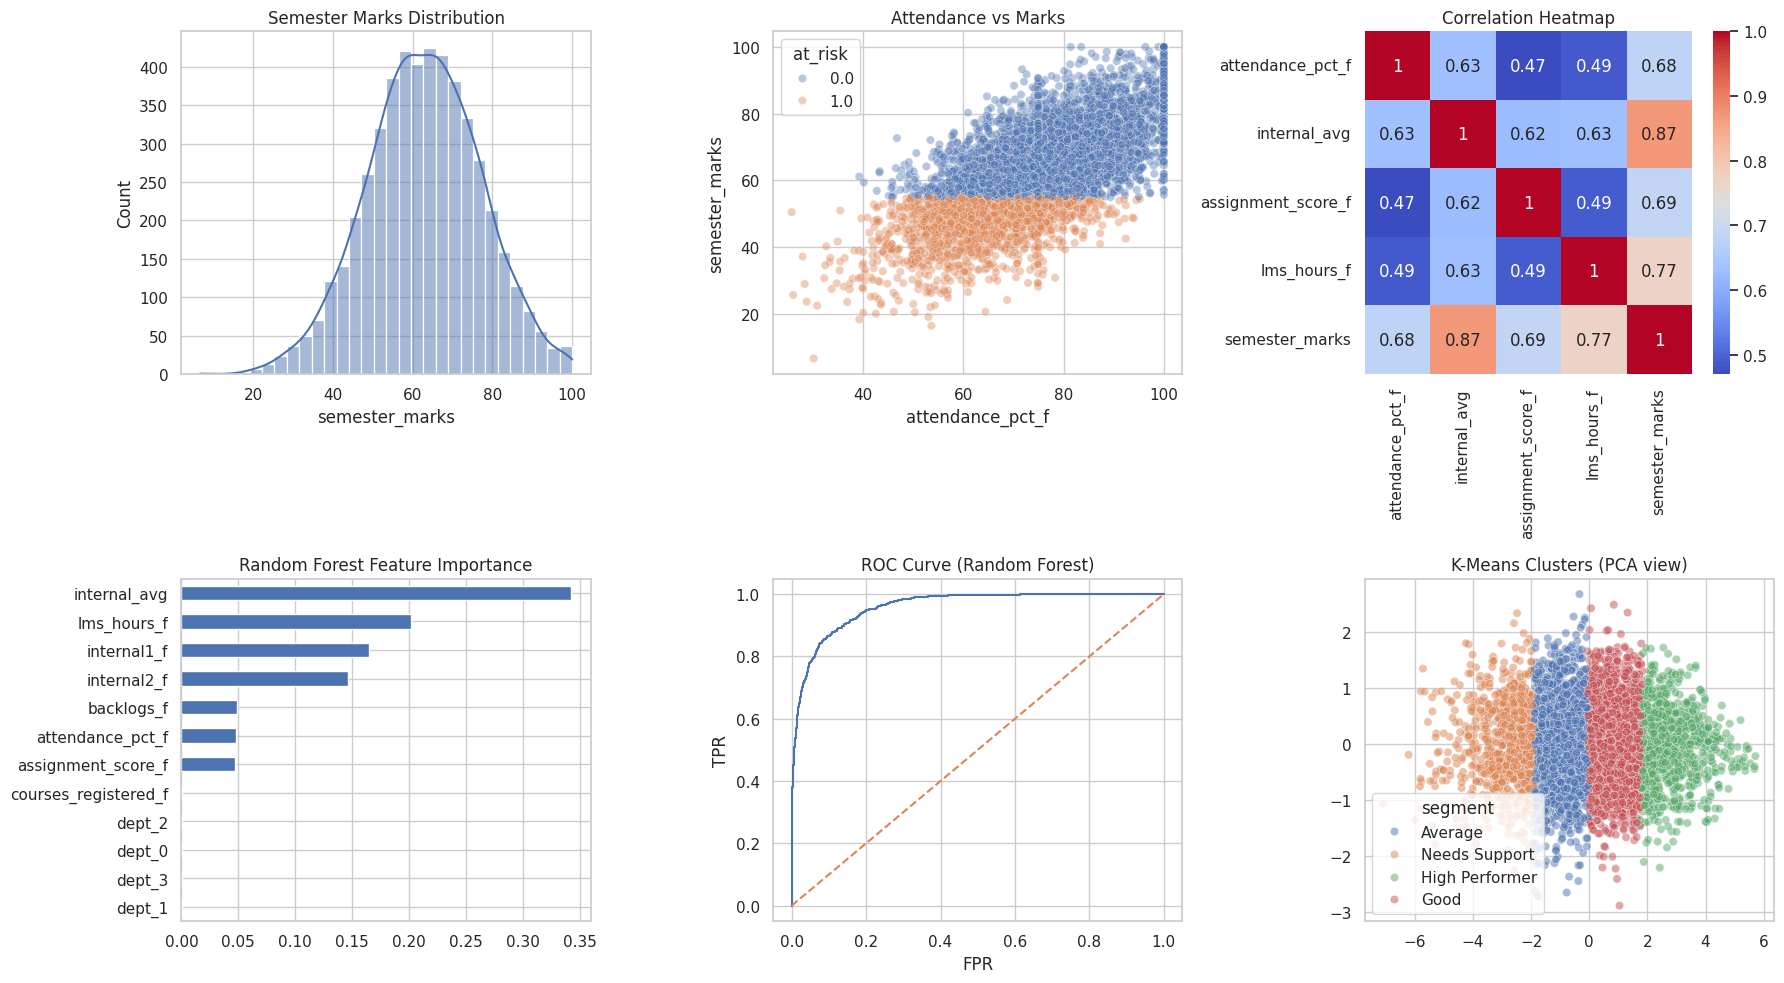

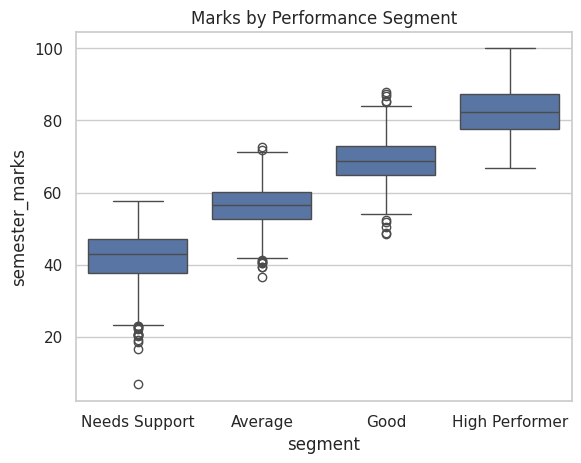

In [9]:
import matplotlib.pyplot as plt, seaborn as sns, numpy as np, pandas as pd
from pyspark.ml.functions import vector_to_array
from sklearn.metrics import roc_curve, confusion_matrix
from sklearn.decomposition import PCA
sns.set_theme(style="whitegrid")

pdf = clustered.sample(0.05, seed=1).select("department","attendance_pct_f","internal_avg","assignment_score_f",
        "lms_hours_f","semester_marks","at_risk","cluster","scaled").toPandas()
pdf["segment"] = pdf["cluster"].map(label_map)
fig, ax = plt.subplots(2, 3, figsize=(18, 10))

sns.histplot(pdf["semester_marks"], bins=30, kde=True, ax=ax[0,0]).set_title("Semester Marks Distribution")
sns.scatterplot(data=pdf, x="attendance_pct_f", y="semester_marks", hue="at_risk", alpha=.4, ax=ax[0,1]).set_title("Attendance vs Marks")
sns.heatmap(pdf[["attendance_pct_f","internal_avg","assignment_score_f","lms_hours_f","semester_marks"]].corr(),
            annot=True, cmap="coolwarm", ax=ax[0,2]); ax[0,2].set_title("Correlation Heatmap")

# feature importance
names_f = [c+"_f" for c in num_cols] + ["internal_avg"] + [f"dept_{i}" for i in range(len(rf_model.featureImportances) - len(num_cols) - 1)]
imp = pd.Series(rf_model.featureImportances.toArray(), index=names_f).sort_values()
imp.plot.barh(ax=ax[1,0], title="Random Forest Feature Importance")

# ROC + confusion matrix
rp = rf_pred.select("at_risk", vector_to_array("probability")[1].alias("p")).sample(0.2, seed=1).toPandas()
fpr, tpr, _ = roc_curve(rp["at_risk"], rp["p"])
ax[1,1].plot(fpr, tpr); ax[1,1].plot([0,1],[0,1],"--"); ax[1,1].set_title("ROC Curve (Random Forest)")
ax[1,1].set_xlabel("FPR"); ax[1,1].set_ylabel("TPR")

# clusters in 2D using PCA
xy = PCA(2).fit_transform(np.array(pdf["scaled"].apply(lambda v: v.toArray()).tolist()))
sns.scatterplot(x=xy[:,0], y=xy[:,1], hue=pdf["segment"], alpha=.5, ax=ax[1,2]).set_title("K-Means Clusters (PCA view)")
plt.tight_layout(); plt.savefig("dashboard.png", dpi=150); plt.show()

# extra: confusion matrix and cluster profile
cm = confusion_matrix(pdf["at_risk"], (pdf["cluster"].map(label_map)=="Needs Support").astype(float))
sns.boxplot(data=pdf, x="segment", y="semester_marks", order=names); plt.title("Marks by Performance Segment"); plt.show()

7. Faculty insights

In [10]:
risk = (rf_model.transform(clustered.drop("rawPrediction","probability","prediction"))
        .withColumn("risk_prob", F.round(vector_to_array("probability")[1], 3))
        .withColumn("segment", F.col("cluster")))

alerts = (risk.filter(F.col("risk_prob") > 0.7)
          .select("student_id","department","attendance_pct_f","internal_avg","lms_hours_f","backlogs_f","risk_prob","cluster")
          .orderBy(F.desc("risk_prob")))
print("Students flagged for academic support:", alerts.count())
alerts.show(10)

alerts.toPandas().to_csv("students_needing_support.csv", index=False)
from google.colab import files; files.download("students_needing_support.csv")

Students flagged for academic support: 20658
+----------+----------+----------------+------------------+-----------+----------+---------+-------+
|student_id|department|attendance_pct_f|      internal_avg|lms_hours_f|backlogs_f|risk_prob|cluster|
+----------+----------+----------------+------------------+-----------+----------+---------+-------+
|     45384|       CSE|            55.5|             32.05|        0.0|       1.0|    0.982|      0|
|      3823|       CSE|            47.8|32.599999999999994|        4.9|       2.0|    0.982|      0|
|     23534|       CSE|            55.3|              23.8|        0.0|       2.0|    0.982|      0|
|     64141|       CSE|            30.1|             28.55|        1.7|       2.0|    0.982|      0|
|     21085|        ME|            38.3|             21.65|        0.0|       1.0|    0.982|      0|
|      7881|        CE|            17.8|              12.7|        9.6|       2.0|    0.982|      0|
|     28180|        ME|            52.9|      

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>